In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#linear regression
def FeatureScaling(x,mean,std):
    return (x -mean)/np.std(x,axis=0)
def SplitData(data,ratio=0.8):
    x = data['data']
    y = data['target']
    num,_ = x.shape
    random_idx = np.random.permutation(num)
    # x = np.array(x.drop(columns=['MedHouseVal']))
    x_train = x[random_idx[0:int(ratio*num)]]
    x_test = x[random_idx[int(ratio*num):]]
    mean_train = np.mean(x_train,axis=0)
    std_train = np.std(x_train,axis=0)
    x_train = FeatureScaling(x_train,mean_train,std_train)
    x_test = FeatureScaling(x_test,mean_train,std_train)
    y_train = y[random_idx[0:int(ratio*num)]]
    y_test = y[random_idx[int(ratio*num):]]
    return x_train,y_train,x_test,y_test

In [3]:
from sklearn.datasets import fetch_openml
dirty_data = fetch_openml('titanic', version=1, as_frame=True, parser='auto')
df = dirty_data.frame
# df = pd.DataFrame(df)
print(df.isna().sum())
print(df.dtypes)


pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64
pclass          int64
survived     category
name              str
sex          category
age           float64
sibsp           int64
parch           int64
ticket            str
fare          float64
cabin             str
embarked     category
boat              str
body          float64
home.dest         str
dtype: object


In [4]:
raw_frame = dirty_data.frame
df = raw_frame.copy()
#drop column ที่ไม่เกี่ยวกับการ classification
df = df.drop(columns=['survived','name','ticket','home.dest'])
#drop column ที่ Nan เยอะมากๆ
df = df.drop(columns=['cabin','body','boat'])
#เติม feature ที่มี null
print(f'features filled age = {df.groupby(['pclass', 'sex'])['age'].transform('median').unique()}\n fare = {df['fare'].median()}')
print(f'embarked = {df['embarked'].mode()[0]}')
# df['age'] = df['age'].fillna(df['age'].median())
df['age'] = df['age'].fillna(
    df.groupby(['pclass', 'sex'])['age'].transform('median'))
df['fare'] = df['fare'].fillna(df['fare'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
#mapping str to int
mapping = {'male':0,'female':1}
# print(np.unique(df['sex'],return_index = True)[0])
df['sex'] = df['sex'].map(mapping).astype(int)
df = pd.get_dummies(df, columns=['embarked'], drop_first=True, dtype=int)
df['is_alone'] = (df['sibsp']+df['parch']==0).astype(int)
df = df.drop(columns=['sibsp','parch'])
print(df.isna().sum())
print(df.head(5))
x = np.array(df)
y = np.array(raw_frame['survived'].astype(int))
data = {'data':x,'target':y,'feature_names':df.columns}
print(data)

features filled age = [36.  42.  29.5 28.  25.  22. ]
 fare = 14.4542
embarked = S
pclass        0
sex           0
age           0
fare          0
embarked_Q    0
embarked_S    0
is_alone      0
dtype: int64
   pclass  sex      age      fare  embarked_Q  embarked_S  is_alone
0       1    1  29.0000  211.3375           0           1         1
1       1    0   0.9167  151.5500           0           1         0
2       1    1   2.0000  151.5500           0           1         0
3       1    0  30.0000  151.5500           0           1         0
4       1    1  25.0000  151.5500           0           1         0
{'data': array([[ 1.    ,  1.    , 29.    , ...,  0.    ,  1.    ,  1.    ],
       [ 1.    ,  0.    ,  0.9167, ...,  0.    ,  1.    ,  0.    ],
       [ 1.    ,  1.    ,  2.    , ...,  0.    ,  1.    ,  0.    ],
       ...,
       [ 3.    ,  0.    , 26.5   , ...,  0.    ,  0.    ,  1.    ],
       [ 3.    ,  0.    , 27.    , ...,  0.    ,  0.    ,  1.    ],
       [ 3.    ,  0.   

In [5]:
epoch = 1000
alpha = 0.01

def LinearRegression(data,epoch,alpha):
  history = list()
  x_train,y_train,x_test,y_test = SplitData(data)
  num,di = x_train.shape
  w = np.ones(di)/num
  b = 0
  for i in range(epoch):
      yt = np.dot(x_train,w) + b
      # print(yt.shape)
      MSE = np.mean((yt-y_train)**2)
      history.append(MSE)
      # update w and b
      dw = (2/int(num))*np.dot(x_train.T,(yt-y_train))
      db = (2/(int(num)))*np.sum(yt-y_train)
      w = w - alpha*dw
      b = b - alpha*db
  xlabel = list(range(len(x_train)))
  print(f'final MSE = {history[-1]}')
  plt.plot(list(range(epoch)),history,label = 'MSE')
  plt.legend()
  plt.show()
  ytt = np.dot(x_test,w) + b
  MSE_t = np.mean((ytt-y_test)**2)
  print(f'MSE test = {MSE_t}')
# LinearRegression(data,epoch,alpha)

final Loss = 0.48254959859634894


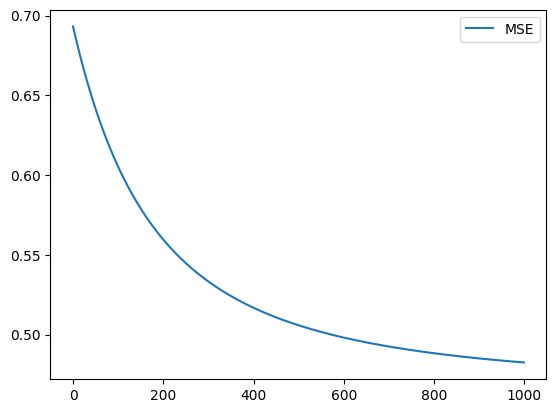

Accuracy test = 80.1526717557252


In [6]:
def LogisticRegression(data,epoch,alpha):
  def sigmoid(z):
      return 1/(1+np.exp(-z))
  # logistic regression
  history = list()
  x_train,y_train,x_test,y_test = SplitData(data)
  num,di = x_train.shape
  w = np.ones(di)/num
  b = 0
  for i in range(epoch):
      yt = sigmoid(np.dot(x_train,w) + b)
      # yt = (yt>0.5).astype(int)
      # print(yt.shape)
      Loss = -np.mean(y_train*np.log(yt+1e-15)+(1-y_train)*np.log(1-yt+1e-15))
      history.append(Loss)
      # update w and b
      dw = (1/int(num))*np.dot(x_train.T,(yt-y_train))
      db = (1/(int(num)))*np.sum(yt-y_train)
      w = w - alpha*dw
      b = b - alpha*db

  xlabel = list(range(len(x_train)))
  print(f'final Loss = {history[-1]}')
  plt.plot(list(range(epoch)),history,label = 'MSE')
  plt.legend()
  plt.show()
  ytt = sigmoid(np.dot(x_test,w) + b)
  ytt = (ytt>0.5).astype(int)
  acc_t = np.mean(ytt == y_test) * 100
  print(f'Accuracy test = {acc_t}')
LogisticRegression(data,epoch,alpha)

final Loss = 0.5198514747945765


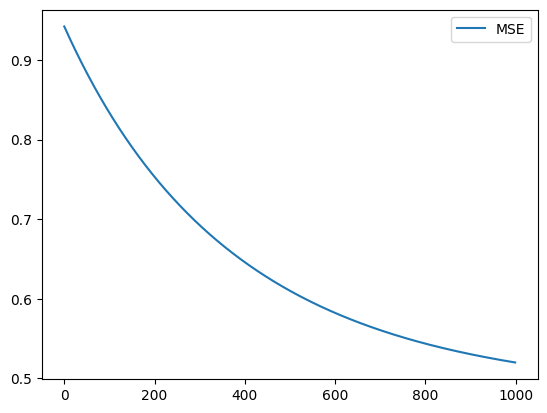

Accuracy test = 74.80916030534351


In [7]:
# multi layer percupton (MLP)
def sigmoid(z):
    return 1/(1+np.exp(-z))

history = list()
x_train,y_train,x_test,y_test = SplitData(data)
num,di = x_train.shape
y_train = y_train.reshape((num,1))
y_test = y_test.reshape(-1, 1)
nh = 16
alpha = 0.01
w1 = np.random.randn(di*nh).reshape((di,nh))
b1 = np.random.rand(1,nh)
w2 = np.random.randn(nh).reshape((nh,1))
b2 = np.random.rand()
epoch = 1000
for i in range(epoch):
    z1 = np.dot(x_train,w1) + b1
    A1 = sigmoid(z1)
    z2 = np.dot(A1,w2)+b2
    yt = sigmoid(z2)
    Loss = -np.mean(y_train*np.log(yt+1e-15)+(1-y_train)*np.log(1-yt+1e-15))
    history.append(Loss)

    # update w and b
    dz2 = yt - y_train
    dw2 = (1/int(num))*np.dot(A1.T,dz2)
    db2 = (1/(int(num)))*np.sum(dz2,axis=0,keepdims=True)
    dz1 = np.dot(dz2, w2.T) * (A1 * (1 - A1))
    dw1 = (1/num) * np.dot(x_train.T, dz1)
    db1 = (1/num) * np.sum(dz1, axis=0, keepdims=True)
    w2 = w2 - alpha*dw2
    b2 = b2 - alpha*db2
    w1 = w1 - alpha*dw1
    b1 = b1 - alpha*db1

xlabel = list(range(len(x_train)))
print(f'final Loss = {history[-1]}')
plt.plot(list(range(epoch)),history,label = 'MSE')
plt.legend()
plt.show()
z1 = np.dot(x_test,w1) + b1
A1 = sigmoid(z1)
z2 = np.dot(A1,w2)+b2
ytt = sigmoid(z2)
# print(z1.shape,yt.shape)
Loss = -np.mean(y_test*np.log(ytt+1e-15)+(1-y_test)*np.log(1-ytt+1e-15))
ytt = (ytt>0.5).astype(int)
acc_t = np.mean(ytt == y_test) * 100
print(f'Accuracy test = {acc_t}')

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.regularizers import l2

#Binary MLP using tensorflow
x_train,y_train,x_test,y_test = SplitData(data)
num,di = x_train.shape
y_train = y_train.reshape((num,1))
y_test = y_test.reshape(-1, 1)
nh = 32
n_epoch = 150
alpha = 0.001
model = Sequential([
    Input(shape=(di,)),
    Dense(nh, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(nh//2, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(nh//4, activation='relu'),
    Dense(1, activation='sigmoid'),  # ชั้นคำตอบสุดท้ายต้องเป็น sigmoid
])
# print(model)

# 2. ตั้งค่า Optimizer และ Loss Function
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=alpha),
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

# 3. เทรนโมเดล (แทนลูป for เดิม)
history = model.fit(
    x_train,
    y_train,
    epochs=n_epoch,
    batch_size=32,
    validation_data=(x_test, y_test),
    verbose=1,  # ตั้งเป็น 0 หากไม่อยากให้ปริ้นท์ข้อความยาวๆ ในแต่ละรอบ
)

C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.4.0) or chardet (7.6.0)/charset_normalizer (3.4.2) doesn't match a supported version!
  warnings.warn(


Epoch 1/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.5748 - loss: 0.7587 - val_accuracy: 0.6756 - val_loss: 0.6737
Epoch 2/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6763 - loss: 0.6448 - val_accuracy: 0.7252 - val_loss: 0.6405
Epoch 3/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6834 - loss: 0.6130 - val_accuracy: 0.7137 - val_loss: 0.6133
Epoch 4/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7146 - loss: 0.5773 - val_accuracy: 0.7137 - val_loss: 0.5893
Epoch 5/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7525 - loss: 0.5659 - val_accuracy: 0.7443 - val_loss: 0.5679
Epoch 6/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7543 - loss: 0.5416 - val_accuracy: 0.7443 - val_loss: 0.5481
Epoch 7/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7667 - loss: 0.5418 - val_accuracy: 0.7481 - val_loss: 0.5305
Epoch 8/150
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7906 - loss: 0.5008 - val_accuracy: 0.7901 - 

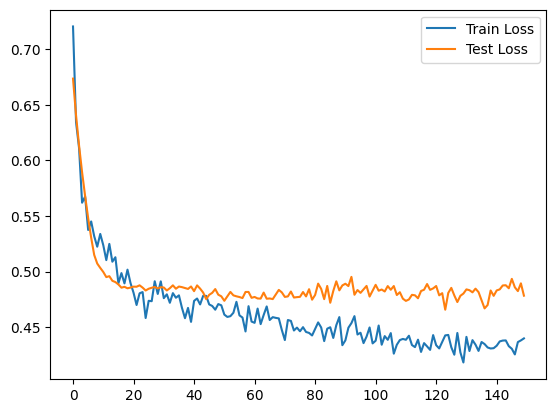

Test Loss = 0.4783 | Test Accuracy = 78.63%


In [9]:
# 4. พล็อตกราฟ Loss ของ Train เทียบกับ Test
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.legend()
plt.show()

# 5. วัดผลความแม่นยำสุดท้ายบนชุด Test
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f'Test Loss = {test_loss:.4f} | Test Accuracy = {test_acc*100:.2f}%')

In [10]:
#create decision tree
def gini_impurity(y):
  _,counts = np.unique(y,return_counts=True)
  gini = 1- np.sum((counts/len(y))**2)
  return gini
# y = np.array([0,1])
x_train,y_train,x_test,y_test = SplitData(data)
num,di = x_train.shape
def best_split(x,y,num_features):
  if num_features is None:
    num_features = x.shape[1]
  num,di = x.shape
  features = np.random.choice(di,num_features,replace=False)
  features = np.sort(features)
  best_gini = 1e10
  bestCol = None
  bestTh = None
  for feature in features:
    thresholds = np.unique(x[:,feature])
    for threshold in thresholds:
      x_l = y[x[:,feature] <= threshold]
      x_r = y[x[:,feature] > threshold]
      weighted_gini = (len(x_l)/num)*gini_impurity(x_l) + (len(x_r)/num)*gini_impurity(x_r)
      if len(x_l) == 0 or len(x_r)==0:
        continue
      if weighted_gini < best_gini:
        bestTh = threshold ; bestCol = feature ; best_gini = weighted_gini
  return bestCol,bestTh
print(best_split(x_train,y_train,di))

def build_tree(x, y, depth=0, max_depth=3, num_features=None):
  # ถ้าไม่ได้ระบุ num_features ให้ใช้จำนวนคอลัมน์ทั้งหมดของ x
  if num_features is None:
    num_features = x.shape[1]

  # 1. เงื่อนไขหยุดแตกกิ่ง (Base Case -> คืนค่าเป็นตัวเลขคลาสที่พบมากที่สุด)
  if depth >= max_depth or len(np.unique(y)) == 1 or len(y) < 2:
    vals, counts = np.unique(y, return_counts=True)
    return vals[np.argmax(counts)]

  # 2. หาคอลัมน์และจุดตัดที่ดีที่สุดจากฟังก์ชัน best_split ของคุณ
  col, thresh = best_split(x, y, num_features)

  # กรณีพิเศษ: ถ้าข้อมูลทุกแถวซ้ำกันจนหาจุดตัดไม่ได้ ให้คืนค่าคลาสที่พบมากที่สุด
  if col is None:
    vals, counts = np.unique(y, return_counts=True)
    return vals[np.argmax(counts)]

  # 3. สร้างตัวกรอง (Mask) แยกข้อมูลฝั่งซ้าย (<= thresh) และฝั่งขวา (> thresh)
  left_mask = x[:, col] <= thresh
  right_mask = x[:, col] > thresh

  # กันกรณีที่แบ่งแล้วฝั่งใดฝั่งหนึ่งไม่มีข้อมูลเลย
  if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
    vals, counts = np.unique(y, return_counts=True)
    return vals[np.argmax(counts)]

  # 4. เรียกฟังก์ชันตัวเองซ้ำ (Recursion) เพื่อสร้างกิ่งซ้ายและกิ่งขวา โดยเพิ่ม depth + 1
  left_branch = build_tree(
      x[left_mask], y[left_mask], depth + 1, max_depth, num_features
  )
  right_branch = build_tree(
      x[right_mask], y[right_mask], depth + 1, max_depth, num_features
  )

  # 5. คืนค่าเป็น Dictionary ของกิ่งนี้
  return {
      'col': col,
      'thresh': thresh,
      'left': left_branch,
      'right': right_branch,
  }
# print(build_tree(x_train,y_train,max_depth=3))

(1, -0.7470178808339949)


In [11]:
# 1. สร้างต้นไม้จากข้อมูล Train (กำหนดความลึกสูงสุด max_depth=3)
my_tree = build_tree(x_train, y_train, depth=0, max_depth=3, num_features=di)
print('โครงสร้างต้นไม้ที่ได้:\n', my_tree)


# 2. ฟังก์ชันเดินตามกิ่งไม้เพื่อทำนายข้อมูล 1 แถว
def predict_row(tree, row):
  if not isinstance(tree, dict):  # ถ้าเจอใบไม้ (ตัวเลขคลาส) ให้ส่งคำตอบกลับเลย
    return tree
  if row[tree['col']] <= tree['thresh']:
    return predict_row(tree['left'], row)  # ถ้า <= จุดตัด ให้ไปกิ่งซ้าย
  else:
    return predict_row(tree['right'], row)  # ถ้า > จุดตัด ให้ไปกิ่งขวา


# 3. นำไปทำนาย x_test ทุกแถวและวัด Accuracy
y_pred = np.array([predict_row(my_tree, row) for row in x_test])
accuracy = np.mean(y_pred == y_test) * 100
print(f'Test Accuracy = {accuracy:.2f}%')

โครงสร้างต้นไม้ที่ได้:
 {'col': 1, 'thresh': -0.7470178808339949, 'left': {'col': 2, 'thresh': -1.5406412769586915, 'left': {'col': 0, 'thresh': -0.3495849337269851, 'left': 1, 'right': 0}, 'right': {'col': 3, 'thresh': -0.13569544763681524, 'left': 0, 'right': 0}}, 'right': {'col': 0, 'thresh': -0.3495849337269851, 'left': {'col': 3, 'thresh': -0.03055077439315443, 'left': 1, 'right': 1}, 'right': {'col': 3, 'thresh': -0.21106410689828187, 'left': 1, 'right': 0}}}
Test Accuracy = 78.24%


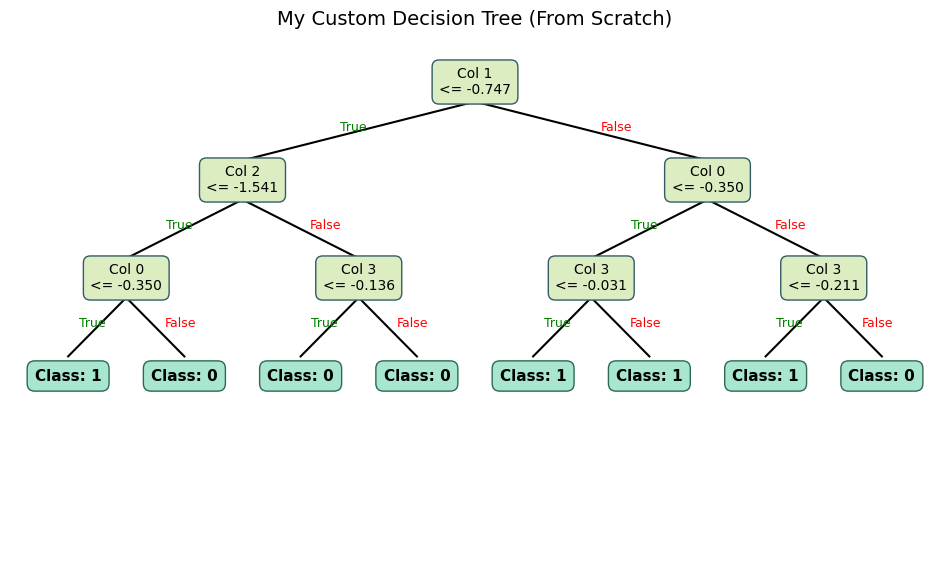

In [12]:
import matplotlib.pyplot as plt


def plot_custom_tree(
    tree,
    feature_names=None,
    class_names=None,
    x=0.5,
    y=1.0,
    dx=0.25,
    dy=0.2,
    ax=None,
):
  if ax is None:
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.1)
    ax.axis('off')

  # กรณีเป็นใบไม้ (Leaf Node -> แสดงคลาสที่ทำนาย)
  if not isinstance(tree, dict):
    label = (
        f'Class: {class_names[int(tree)]}'
        if class_names is not None
        else f'Class: {int(tree)}'
    )
    ax.text(
        x,
        y,
        label,
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        bbox=dict(
            boxstyle='round,pad=0.5', facecolor='#a8e6cf', edgecolor='#2d6a4f'
        ),
    )
    return

  # กรณีเป็นกิ่งคำถาม (Decision Node -> แสดงชื่อคอลัมน์และจุดตัด)
  col_idx = int(tree['col'])
  col_name = feature_names[col_idx] if feature_names is not None else f'Col {col_idx}'
  label = f"{col_name}\n<= {tree['thresh']:.3f}"
  ax.text(
      x,
      y,
      label,
      ha='center',
      va='center',
      fontsize=10,
      bbox=dict(
          boxstyle='round,pad=0.5', facecolor='#dcedc1', edgecolor='#335c67'
      ),
  )

  # คำนวณตำแหน่งของกิ่งซ้าย (True) และกิ่งขวา (False)
  x_left, x_right = x - dx, x + dx
  y_next = y - dy

  # วาดเส้นเชื่อมและข้อความ True / False
  ax.plot([x, x_left], [y - 0.04, y_next + 0.04], 'k-', lw=1.5)
  ax.text(
      (x + x_left) / 2 - 0.02,
      (y + y_next) / 2,
      'True',
      fontsize=9,
      color='green',
  )

  ax.plot([x, x_right], [y - 0.04, y_next + 0.04], 'k-', lw=1.5)
  ax.text(
      (x + x_right) / 2 + 0.01,
      (y + y_next) / 2,
      'False',
      fontsize=9,
      color='red',
  )

  # เรียกซ้ำเพื่อวาดกิ่งซ้ายและกิ่งขวา
  plot_custom_tree(
      tree['left'], feature_names, class_names, x_left, y_next, dx / 2, dy, ax
  )
  plot_custom_tree(
      tree['right'], feature_names, class_names, x_right, y_next, dx / 2, dy, ax
  )


# เรียกใช้งานกับ my_tree ของคุณ (สามารถส่งชื่อคอลัมน์และชื่อคลาสเข้าไปได้)
plot_custom_tree(my_tree)
plt.title('My Custom Decision Tree (From Scratch)', fontsize=14)
plt.show()

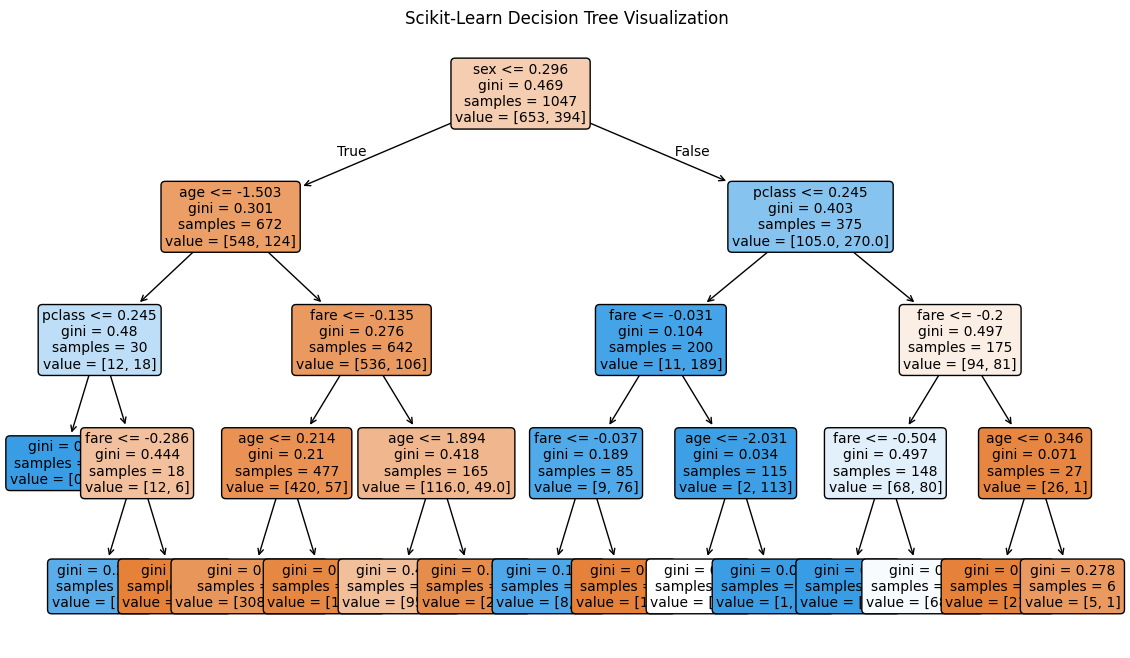

DecisionTreeClassifier(max_depth=4, random_state=42)


In [13]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# สร้างและเทรน Decision Tree ของ sklearn ด้วยความลึก max_depth=3 เท่ากัน
sk_tree = DecisionTreeClassifier(max_depth=4, criterion='gini', random_state=42)
sk_tree.fit(x_train, y_train)
# print(data)
# วาดแผนผังต้นไม้
plt.figure(figsize=(14, 8))
plot_tree(
    sk_tree,
    feature_names=data['feature_names'],  # เปลี่ยนตามชื่อตัวแปร dataset ที่คุณใช้
    # class_names=list(data['target_names']),
    filled=True,  # ระบายสีตามคลาสอัตโนมัติ (ยิ่งสีเข้ม แปลว่าค่า Gini ยิ่งต่ำ/บริสุทธิ์)
    rounded=True,
    fontsize=10,
)
plt.title('Scikit-Learn Decision Tree Visualization')
plt.show()
print(sk_tree)

In [14]:
def build_forest(x, y, n_trees=150, max_depth=3):
  num, di = x.shape
  num_features = int(np.sqrt(di))  # สุ่มพิจารณาแค่รากที่สองของจำนวนคอลัมน์ทั้งหมด
  forest = []

  for _ in range(n_trees):
    # 1. สุ่มดัชนีแถวแบบใส่คืน (Bootstrap: หยิบซ้ำได้)
    boot_idx = np.random.choice(num, num, replace=True)
    x_boot = x[boot_idx]
    y_boot = y[boot_idx]

    # 2. สร้างต้นไม้ 1 ต้นจากข้อมูลที่สุ่มมา แล้วเก็บเข้าป่า
    tree = build_tree(
        x_boot, y_boot, depth=0, max_depth=max_depth, num_features=num_features
    )
    forest.append(tree)
  return forest
def predict_forest(forest,x_test):
  prediction = []
  for row in x_test:
    votes = [predict_row(tree,row) for tree in forest]
    vals, counts = np.unique(votes,return_counts=True)
    pred = vals[np.argmax(counts)]
    prediction.append(pred)
  return np.array(prediction)

my_forest = build_forest(x_train, y_train, n_trees=120, max_depth=4)
y_pred = predict_forest(my_forest,x_test)
accuracy = np.mean(y_pred == y_test) * 100
print(f'Test Accuracy = {accuracy:.2f}%')



Test Accuracy = 74.43%


In [28]:
from sklearn.ensemble import RandomForestClassifier
x_train,y_train,x_test,y_test = SplitData(data)
my_forest = RandomForestClassifier(n_estimators=120,max_depth=3,random_state=42)
my_forest = my_forest.fit(x_train,y_train)
y_pred_rf = my_forest.predict(x_test)
acc_rf = np.mean(y_pred_rf == y_test) * 100
print(f"Scikit-Learn Random Forest Accuracy = {acc_rf:.2f}%")

Scikit-Learn Random Forest Accuracy = 81.30%
